# 05 · Regression: how large will a buyer's order be?
**Business problem:** campaign target quantities and supplier negotiations depend on expected order value. **Target:** `G4_Expected_Order_Value_AED`. Intent answers and the conversion score are excluded so that the estimate is available before a buyer has committed.

                         Model     MAE        MSE    RMSE     R2  CV_RMSE_Train
               Baseline (mean) 451.606 405528.764 636.811 -0.004        724.518
    Multiple Linear Regression 321.865 214296.880 462.922  0.469        484.365
Linear Regression (log target) 298.324 215942.415 464.696  0.465        499.293
       Random Forest Regressor 225.002 117008.485 342.065  0.710        358.826
selected Random Forest Regressor


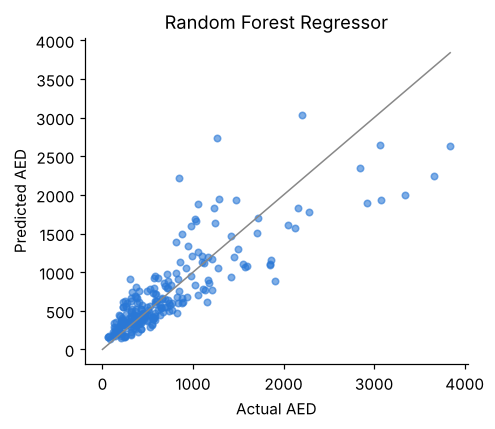

Individual n 207 MAE 163.7 R2 0.626
SME n 33 MAE 609.4 R2 0.321


                      Feature  Importance
B1_Monthly_Spend_Eligible_AED       0.636
                       Is_SME       0.079
                A8_Occupation       0.050
F1_Min_Discount_To_Switch_Pct       0.018
             F2_Max_Wait_Days       0.011
      B6_Max_Delivery_Fee_AED       0.010
       C1_Price_Consciousness       0.009
  B4_Used_Group_Buying_Before       0.009


In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
BLUE,ORANGE,AQUA,YELLOW='#2a78d6','#eb6834','#1baf7a','#eda100'
FIG='../Results/figures/'; SEED=42
c=pd.read_csv('../Dataset/customers.csv')
from sklearn.model_selection import train_test_split,KFold,cross_val_score
from sklearn.pipeline import Pipeline,make_pipeline
from sklearn.compose import ColumnTransformer,TransformedTargetRegressor as T
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error as MAE,mean_squared_error as MSE,r2_score
y=c.G4_Expected_Order_Value_AED
catf=['A8_Occupation','B3_Primary_Channel','B4_Used_Group_Buying_Before']
numf=['Is_SME','A9_SME_Employees','A2_Age','A6_Household_Size','A7_Monthly_Income_AED','B1_Monthly_Spend_Eligible_AED','B2_Online_Orders_Per_Month','B6_Max_Delivery_Fee_AED','C1_Price_Consciousness','C2_Willing_To_Wait_For_Deal','C3_Trust_New_Platforms','C7_Values_Price_Transparency','F1_Min_Discount_To_Switch_Pct','F2_Max_Wait_Days']
X=c[numf+catf]; Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.2,random_state=SEED)
pre=ColumnTransformer([('n',make_pipeline(SimpleImputer(strategy='median'),StandardScaler()),numf),('c',OneHotEncoder(handle_unknown='ignore'),catf)])
models={'Baseline (mean)':DummyRegressor(),'Multiple Linear Regression':LinearRegression(),'Linear Regression (log target)':T(LinearRegression(),func=np.log1p,inverse_func=np.expm1),'Random Forest Regressor':RandomForestRegressor(n_estimators=400,min_samples_leaf=3,random_state=SEED,n_jobs=-1)}
res=[];pipes={};cv=KFold(5,shuffle=True,random_state=SEED)
for n,m in models.items():
    p=Pipeline([('pre',pre),('m',m)]); cvr=-cross_val_score(p,Xtr,ytr,cv=cv,scoring='neg_root_mean_squared_error').mean(); p.fit(Xtr,ytr); pipes[n]=p; h=p.predict(Xte)
    res.append(dict(Model=n,MAE=MAE(yte,h),MSE=MSE(yte,h),RMSE=MSE(yte,h)**.5,R2=r2_score(yte,h),CV_RMSE_Train=cvr))
r=pd.DataFrame(res); r.to_csv('../Results/Regression_Metrics.csv',index=False); print(r.round(3).to_string(index=False))
best=r[~r.Model.str.startswith('Baseline')].sort_values('CV_RMSE_Train').iloc[0].Model; print('selected',best)
h=pipes[best].predict(Xte); out=c.loc[Xte.index,['Customer_ID','Is_SME']].assign(Actual_AED=yte.values,Predicted_AED=h.round(2)); out['Error_AED']=(out.Predicted_AED-out.Actual_AED).round(2); out.to_csv('../Results/Regression_Predictions.csv',index=False)
fig,ax=plt.subplots(figsize=(4.6,4)); ax.scatter(out.Actual_AED,out.Predicted_AED,s=18,alpha=.6,color=BLUE); l=[0,out.Actual_AED.max()]; ax.plot(l,l,color='#888',lw=1); ax.set(xlabel='Actual AED',ylabel='Predicted AED',title=best); plt.tight_layout(); plt.savefig(FIG+'regression_actual_vs_pred.png'); plt.show()
for g,d in out.groupby('Is_SME'): print('SME' if g else 'Individual','n',len(d),'MAE',round(MAE(d.Actual_AED,d.Predicted_AED),1),'R2',round(r2_score(d.Actual_AED,d.Predicted_AED),3))
from sklearn.inspection import permutation_importance
pi=permutation_importance(pipes[best],Xte,yte,scoring='r2',n_repeats=10,random_state=SEED); imp=pd.DataFrame({'Feature':X.columns,'Importance':pi.importances_mean}).sort_values('Importance',ascending=False); imp.to_csv('../Results/Regression_Importance.csv',index=False); print(imp.head(8).round(3).to_string(index=False))

## Model comparison across the project

In [2]:
cl=pd.read_csv('../Results/Classification_Metrics.csv'); kk=pd.read_csv('../Results/Clustering_K_Selection.csv').set_index('k'); ar=pd.read_csv('../Results/Association_Rules.csv')
e=[dict(Task='Classification',Model=x.Model,Metric='F1',Value=x.F1,Other=f'Accuracy {x.Accuracy:.3f}; Precision {x.Precision:.3f}; Recall {x.Recall:.3f}; ROC-AUC {x.ROC_AUC:.3f}') for x in cl.itertuples()]
e+=[dict(Task='Regression',Model=x.Model,Metric='R2',Value=x.R2,Other=f'MAE {x.MAE:.1f}; RMSE {x.RMSE:.1f}; MSE {x.MSE:.0f}') for x in r.itertuples()]
e+=[dict(Task='Clustering',Model='K-Means (k=5)',Metric='Silhouette',Value=kk.silhouette[5],Other=f'Inertia {kk.inertia[5]:.0f}')]
e+=[dict(Task='Association',Model=f'Apriori: {t}',Metric='Max lift',Value=g.lift.max(),Other=f'{len(g)} rules; median confidence {g.confidence.median():.3f}') for t,g in ar.groupby('Rule_Type')]
pd.DataFrame(e).round(4).to_csv('../Results/Model_Evaluation.csv',index=False); print(pd.DataFrame(e).round(3).to_string(index=False))

          Task                          Model     Metric  Value                                                        Other
Classification     Baseline (always majority)         F1  0.000 Accuracy 0.723; Precision 0.000; Recall 0.000; ROC-AUC 0.500
Classification            Logistic Regression         F1  0.699 Accuracy 0.813; Precision 0.631; Recall 0.783; ROC-AUC 0.871
Classification                  Decision Tree         F1  0.633 Accuracy 0.757; Precision 0.543; Recall 0.759; ROC-AUC 0.778
Classification                  Random Forest         F1  0.673 Accuracy 0.777; Precision 0.566; Recall 0.831; ROC-AUC 0.867
    Regression                Baseline (mean)         R2 -0.004                            MAE 451.6; RMSE 636.8; MSE 405529
    Regression     Multiple Linear Regression         R2  0.469                            MAE 321.9; RMSE 462.9; MSE 214297
    Regression Linear Regression (log target)         R2  0.465                            MAE 298.3; RMSE 464.7; MSE 215942


## Business interpretation
Eligible monthly spend is the main driver of order value. Forecast individuals and SMEs separately, because SME errors are far larger. **Automation:** expected paying buyers × predicted order value gives a suggested target quantity for supplier requests.